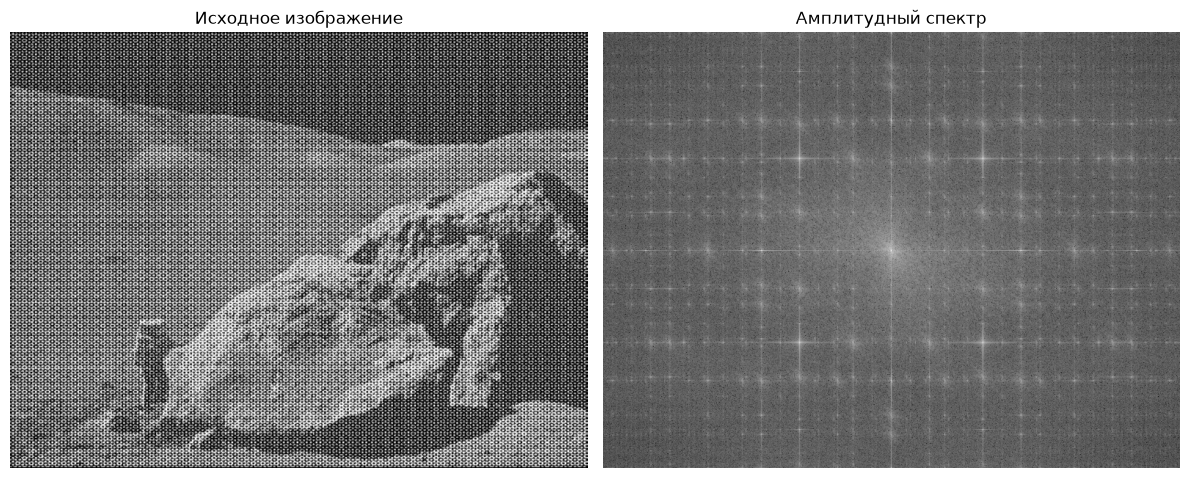

In [7]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('periodic_noise.JPG', cv2.IMREAD_GRAYSCALE)
if img is None:
    img = cv2.imread('periodic_noise.jpg', cv2.IMREAD_GRAYSCALE)

rows, cols = img.shape
cy, cx = rows // 2, cols // 2

f_transform = np.fft.fft2(img)
f_shifted = np.fft.fftshift(f_transform)

spectrum_orig = 20 * np.log(np.abs(f_shifted) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img, cmap='gray')
axes[0].set_title('Исходное изображение')
axes[0].axis('off')

axes[1].imshow(spectrum_orig, cmap='gray')
axes[1].set_title('Амплитудный спектр')
axes[1].axis('off')

plt.tight_layout()
plt.show()

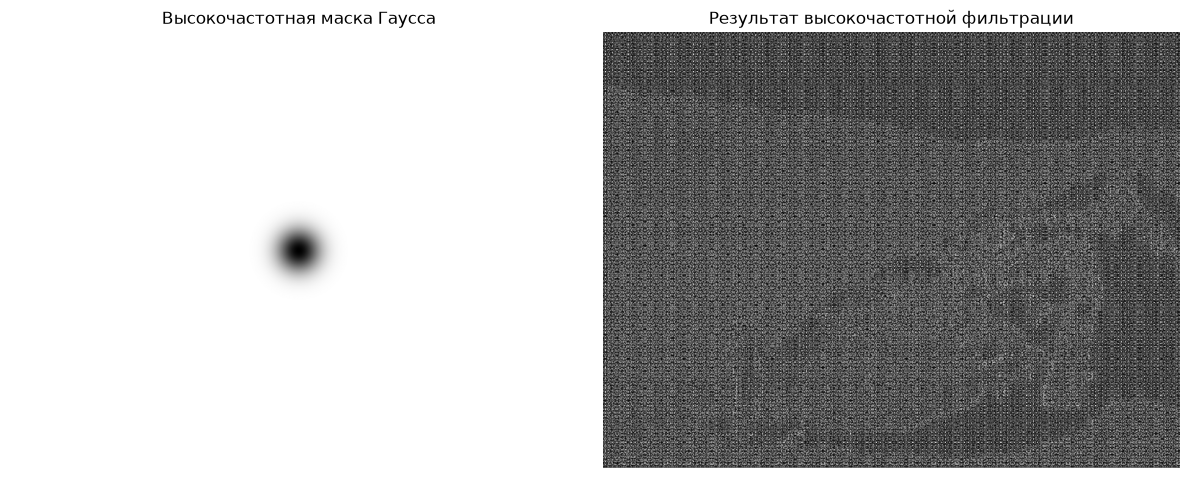

In [8]:
sigma = 20
y, x = np.ogrid[:rows, :cols]
dist_sq = (y - cy)**2 + (x - cx)**2

low_pass_gauss = np.exp(-dist_sq / (2 * sigma**2))
high_pass_gauss = 1.0 - low_pass_gauss

f_hp = f_shifted * high_pass_gauss
img_hp = np.abs(np.fft.ifft2(np.fft.ifftshift(f_hp)))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(high_pass_gauss, cmap='gray')
axes[0].set_title('Высокочастотная маска Гаусса')
axes[0].axis('off')

axes[1].imshow(img_hp, cmap='gray')
axes[1].set_title('Результат высокочастотной фильтрации')
axes[1].axis('off')

plt.tight_layout()
plt.show()

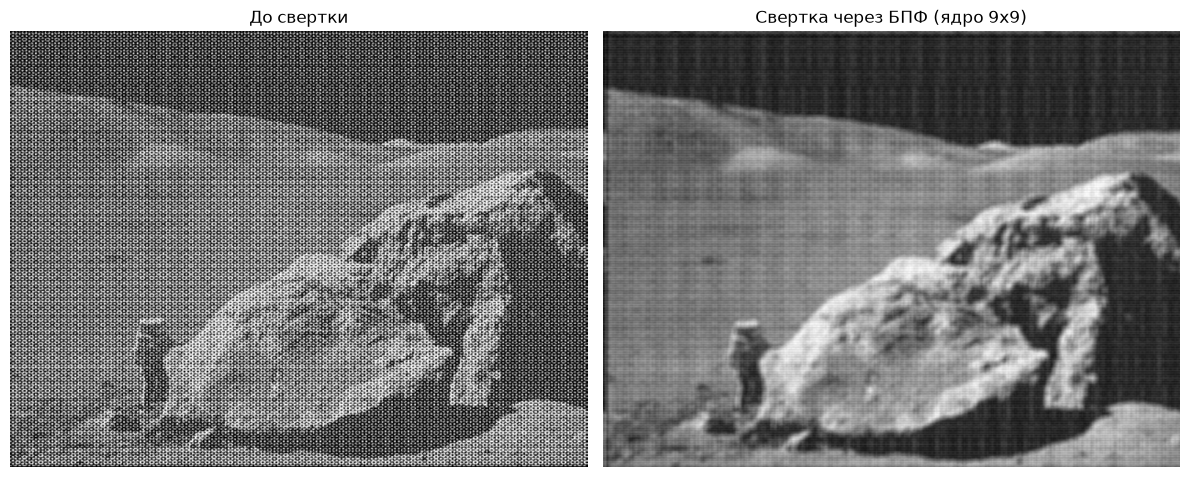

In [9]:
kernel_size = 9
box_kernel = np.ones((kernel_size, kernel_size), dtype=np.float32) / (kernel_size ** 2)

F_img = np.fft.fft2(img, s=(rows, cols))
F_ker = np.fft.fft2(box_kernel, s=(rows, cols))

img_convolved = np.real(np.fft.ifft2(F_img * F_ker))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img, cmap='gray')
axes[0].set_title('До свертки')
axes[0].axis('off')

axes[1].imshow(img_convolved, cmap='gray')
axes[1].set_title(f'Свертка через БПФ (ядро {kernel_size}x{kernel_size})')
axes[1].axis('off')

plt.tight_layout()
plt.show()

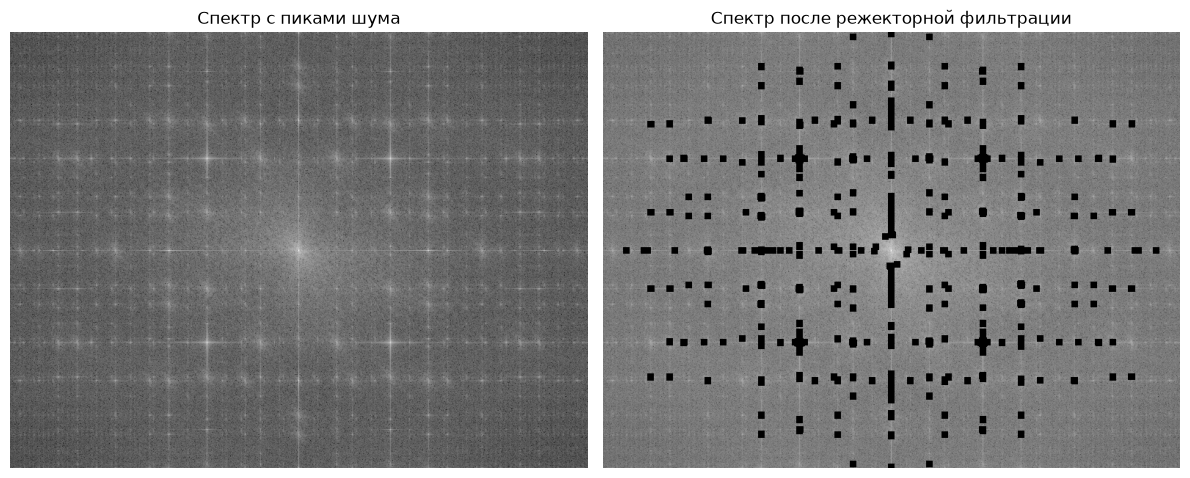

In [10]:
mag_search = np.abs(f_shifted)
mag_search[dist_sq <= 20**2] = 0

threshold = np.percentile(mag_search, 99.8)
noise_peaks = np.argwhere(mag_search > threshold)

f_cleaned = f_shifted.copy()
notch_r = 4
for py, px in noise_peaks:
    y_min, y_max = max(0, py - notch_r), min(rows, py + notch_r + 1)
    x_min, x_max = max(0, px - notch_r), min(cols, px + notch_r + 1)
    f_cleaned[y_min:y_max, x_min:x_max] = 0

spectrum_cleaned = 20 * np.log(np.abs(f_cleaned) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(spectrum_orig, cmap='gray')
axes[0].set_title('Спектр с пиками шума')
axes[0].axis('off')

axes[1].imshow(spectrum_cleaned, cmap='gray')
axes[1].set_title('Спектр после режекторной фильтрации')
axes[1].axis('off')

plt.tight_layout()
plt.show()

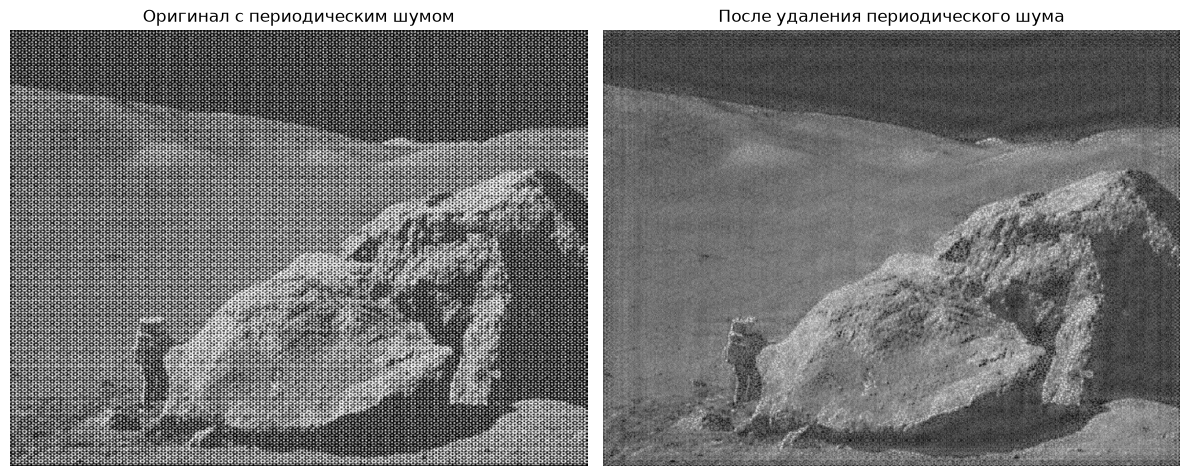

In [11]:
img_restored = np.abs(np.fft.ifft2(np.fft.ifftshift(f_cleaned)))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img, cmap='gray')
axes[0].set_title('Оригинал с периодическим шумом')
axes[0].axis('off')

axes[1].imshow(img_restored, cmap='gray')
axes[1].set_title('После удаления периодического шума')
axes[1].axis('off')

plt.tight_layout()
plt.show()